# GMM Wasserstein Goodness Of Fit

This notebook evaluates fitted per-distribution GMMs by computing:
1. Validation-split distance from the train-vs-validation split for the cells of each patient.
2. A train-split distance between the held-out validation split and the original train cells.
3. A single-Gaussian baseline distance between the held-out validation split and a sampled baseline fit on the train split.
4. A fitted-GMM distance between the held-out validation split and a sample from the persisted GMM.
5. The relative error `(GMM - reference) / (baseline - reference)`.

Implementation notes:
- Exact empirical `W_2^2` uses `ggml_ot.distances.compute_OT(..., squared_ground_cost=True)`.
- The notebook evaluates in the raw fitted representation (`adata.X` or `adata.obsm[use_rep]`) used by `fit_gmm(...)`.
- When fit-time held-out-NLL selection metadata is available, the notebook reconstructs that original deterministic train/validation split from the stored split settings and the config random seed.

In [1]:
import sys
from pathlib import Path

NOTEBOOK_DIR = Path(".").resolve()
REPO_ROOT = NOTEBOOK_DIR.parent

def display_path(path: Path) -> Path:
    return Path("..") / Path(path).resolve().relative_to(REPO_ROOT)

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from _utils.validate_gmm_fit import (
    collect_selected_k_summary,
    evaluate_config_gof,
    load_resolved_config,
    plot_distance_triplet_panels,
    plot_selected_k_histograms,
    plot_train_gmm_panels,
    plot_relative_error_panels,
)

In [2]:
CONFIG_FILE = "config/paper/main_benchmark.yml"

In [3]:
config, resolved_config_path, repo_root = load_resolved_config(CONFIG_FILE, repo_root=REPO_ROOT)
dataset_names = list(config["datasets"].keys())
print(f"Resolved config: {display_path(resolved_config_path)}")
print("Evaluating datasets:", dataset_names)
print("Configured GMM train_size:", config.get("gmm", {}).get("fit_gmm_kwargs", {}).get("train_size"))

Resolved config: ../snakemake/config/paper/main_benchmark.yml
Evaluating datasets: ['kidney', 'COVID', 'breastcancer', 'myocardial_infarction', 'synth_recovery2_jitter', 'synth_recovery2_jitter_onlycov']
Configured GMM train_size: 0.5


In [4]:
OUTPUT_DIR = REPO_ROOT / "data"/"generated_plots"/"appendix"/"gmm_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_plot_pdf(fig, filename: str) -> Path:
    path = OUTPUT_DIR / filename
    fig.savefig(path, bbox_inches="tight")
    print(f"Saved {display_path(path)}")
    return path

print(f"PDF output directory: {display_path(OUTPUT_DIR)}")

PDF output directory: ../data/generated_plots/appendix/gmm_validation


In [5]:
selected_k_summary = collect_selected_k_summary(CONFIG_FILE, repo_root=REPO_ROOT)
selected_k_summary.sort_values(["dataset_display_name", "selected_k", "distribution_id"]).head(100)

,dataset,dataset_display_name,distribution_id,selected_k,selected_k_source,selected_q,selection_metric
209,breastcancer,Breastcancer,P102,5,selection.best_k_by_distribution,None,heldout_nll
219,breastcancer,Breastcancer,P111,5,selection.best_k_by_distribution,None,heldout_nll
225,breastcancer,Breastcancer,P117,5,selection.best_k_by_distribution,None,heldout_nll
235,breastcancer,Breastcancer,P126,5,selection.best_k_by_distribution,None,heldout_nll
238,breastcancer,Breastcancer,P15,5,selection.best_k_by_distribution,None,heldout_nll
...,...,...,...,...,...,...,...
250,breastcancer,Breastcancer,P27,12,selection.best_k_by_distribution,None,heldout_nll
254,breastcancer,Breastcancer,P31,12,selection.best_k_by_distribution,None,heldout_nll
258,breastcancer,Breastcancer,P35,12,selection.best_k_by_distribution,None,heldout_nll
284,breastcancer,Breastcancer,P61,12,selection.best_k_by_distribution,None,heldout_nll


Saved ../data/generated_plots/appendix/gmm_validation/selected_k_component_histograms.pdf


,Dataset,Chosen rank $q$
0,Kidney,n/a (ground truth)
1,COVID,n/a (ground truth)
2,Breastcancer,n/a (ground truth)
3,Myocardial infarction,n/a (ground truth)
4,Synth recovery2 jitter,n/a (ground truth)
5,Synth recovery2 jitter onlycov,n/a (ground truth)


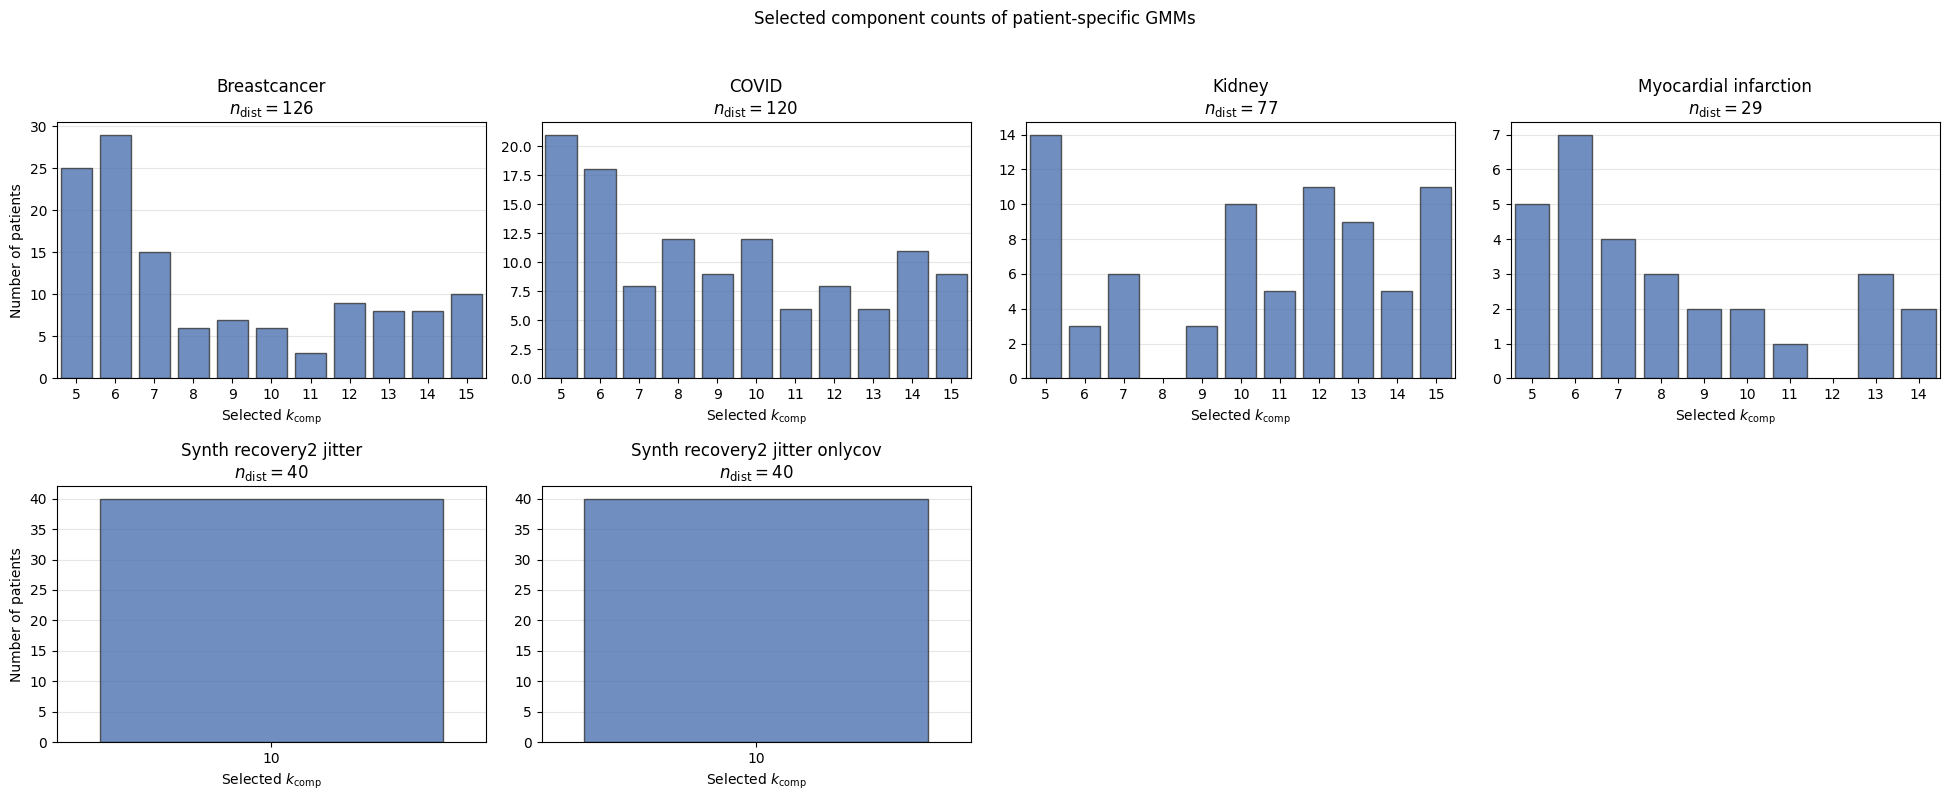

In [6]:
fig_selected_k, _ = plot_selected_k_histograms(
    selected_k_summary,
    dataset_cfg=config["datasets"],
    dataset_names=dataset_names,
)
selected_k_pdf = save_plot_pdf(fig_selected_k, "selected_k_component_histograms.pdf")

selected_q_summary = (
    selected_k_summary.drop_duplicates("dataset")
    .set_index("dataset")
    .reindex(dataset_names)
    .loc[:, ["dataset_display_name", "selected_q"]]
    .assign(selected_q=lambda frame: frame["selected_q"].astype("Int64").astype(str).replace("<NA>", "n/a (ground truth)"))
    .rename(columns={"dataset_display_name": "Dataset", "selected_q": r"Chosen rank $q$"})
    .reset_index(drop=True)
)
selected_q_summary

In [7]:
results, distribution_summary, dataset_summary, metadata = evaluate_config_gof(CONFIG_FILE, repo_root=REPO_ROOT)

print(f"Computed {len(results)} distribution-repeat evaluations.")
metadata

.venv/lib/python3.11/site-packages/ot/lp/_network_simplex.py:574: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  check_result(result_code)


Computed 432 distribution-repeat evaluations.


,dataset,gmm_path,gmm_key,support_source,feature_dim,n_distributions,train_fraction_default,split_source
0,kidney,../data/snakemake/...,gmm_X_pca_100_norm_full_a860b950,raw_representation,100,77,0.5,fit_selection_reconstructed
1,COVID,../data/snakemake/...,gmm_X_pca_100_norm_full_a860b950,raw_representation,100,120,0.5,fit_selection_reconstructed
2,breastcancer,../data/snakemake/...,gmm_X_pca_100_norm_full_a860b950,raw_representation,100,126,0.5,fit_selection_reconstructed
3,myocardial_infarction,../data/snakemake/...,gmm_X_pca_100_norm_full_a860b950,raw_representation,100,29,0.5,fit_selection_reconstructed
4,synth_recovery2_jitter,../data/snakemake/...,gmm_X_20_norm_full_ecdf157c,raw_representation,20,40,0.5,config_fallback
5,synth_recovery2_jitter_onlycov,../data/snakemake/...,gmm_X_20_norm_full_ecdf157c,raw_representation,20,40,0.5,config_fallback


### Reference Distance Diagnostics

`ground_truth_distance` is plotted as the validation-split reference distance. It is a validation-half vs validation-half empirical distance, so it is a noise-floor estimate rather than a guaranteed lower bound.

In [8]:
diagnostics = (
    results.assign(
        gmm_below_ground_truth=results["gmm_distance"] < results["ground_truth_distance"],
        gmm_above_upper_bound=results["gmm_distance"] > results["upper_bound"],
    )
    .groupby("dataset", dropna=False, sort=False)
    .agg(
        n_distributions=("distribution_id", "count"),
        n_gmm_below_ground_truth=("gmm_below_ground_truth", "sum"),
        n_gmm_above_upper_bound=("gmm_above_upper_bound", "sum"),
        mean_relative_error=("relative_error", "mean"),
    )
    .reset_index()
)
diagnostics

,dataset,n_distributions,n_gmm_below_ground_truth,n_gmm_above_upper_bound,mean_relative_error
0,kidney,77,0,6,0.694248
1,COVID,120,0,14,0.614608
2,breastcancer,126,0,5,0.436835
3,myocardial_infarction,29,0,2,0.492233
4,synth_recovery2_jitter,40,24,0,-0.080867
5,synth_recovery2_jitter_onlycov,40,25,0,-0.069725


Saved ../data/generated_plots/appendix/gmm_validation/relative_error_panels.pdf


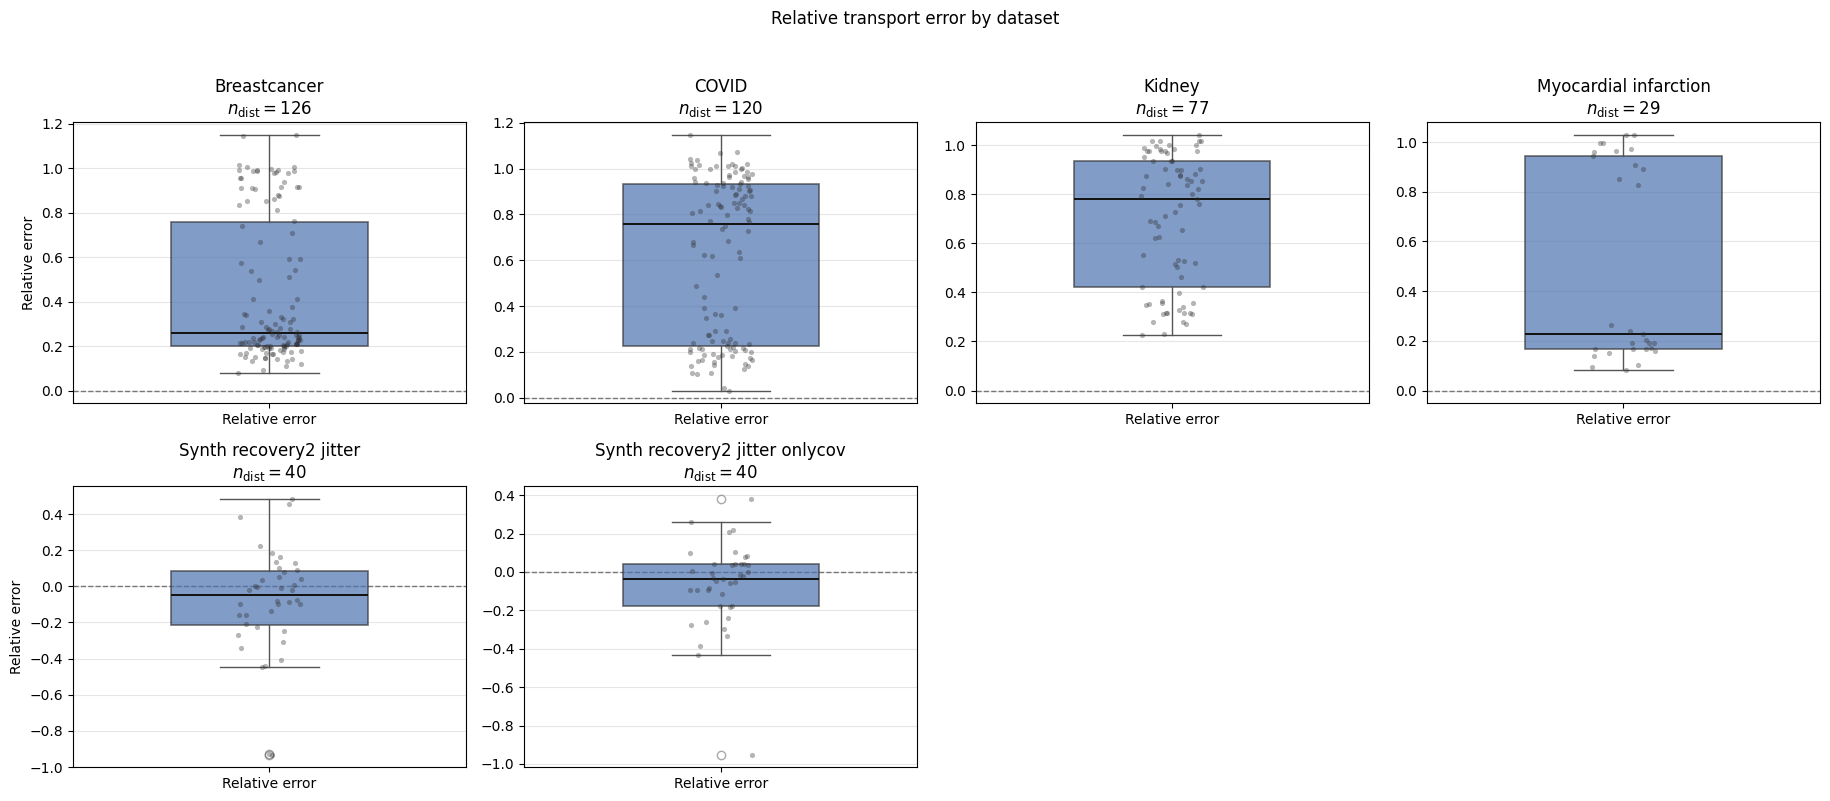

In [9]:
fig_relative, _ = plot_relative_error_panels(
    distribution_summary,
    dataset_cfg=config["datasets"],
    dataset_names=dataset_names,
)
relative_error_pdf = save_plot_pdf(fig_relative, "relative_error_panels.pdf")

Saved ../data/generated_plots/appendix/gmm_validation/validation_distance_triplet_panels.pdf


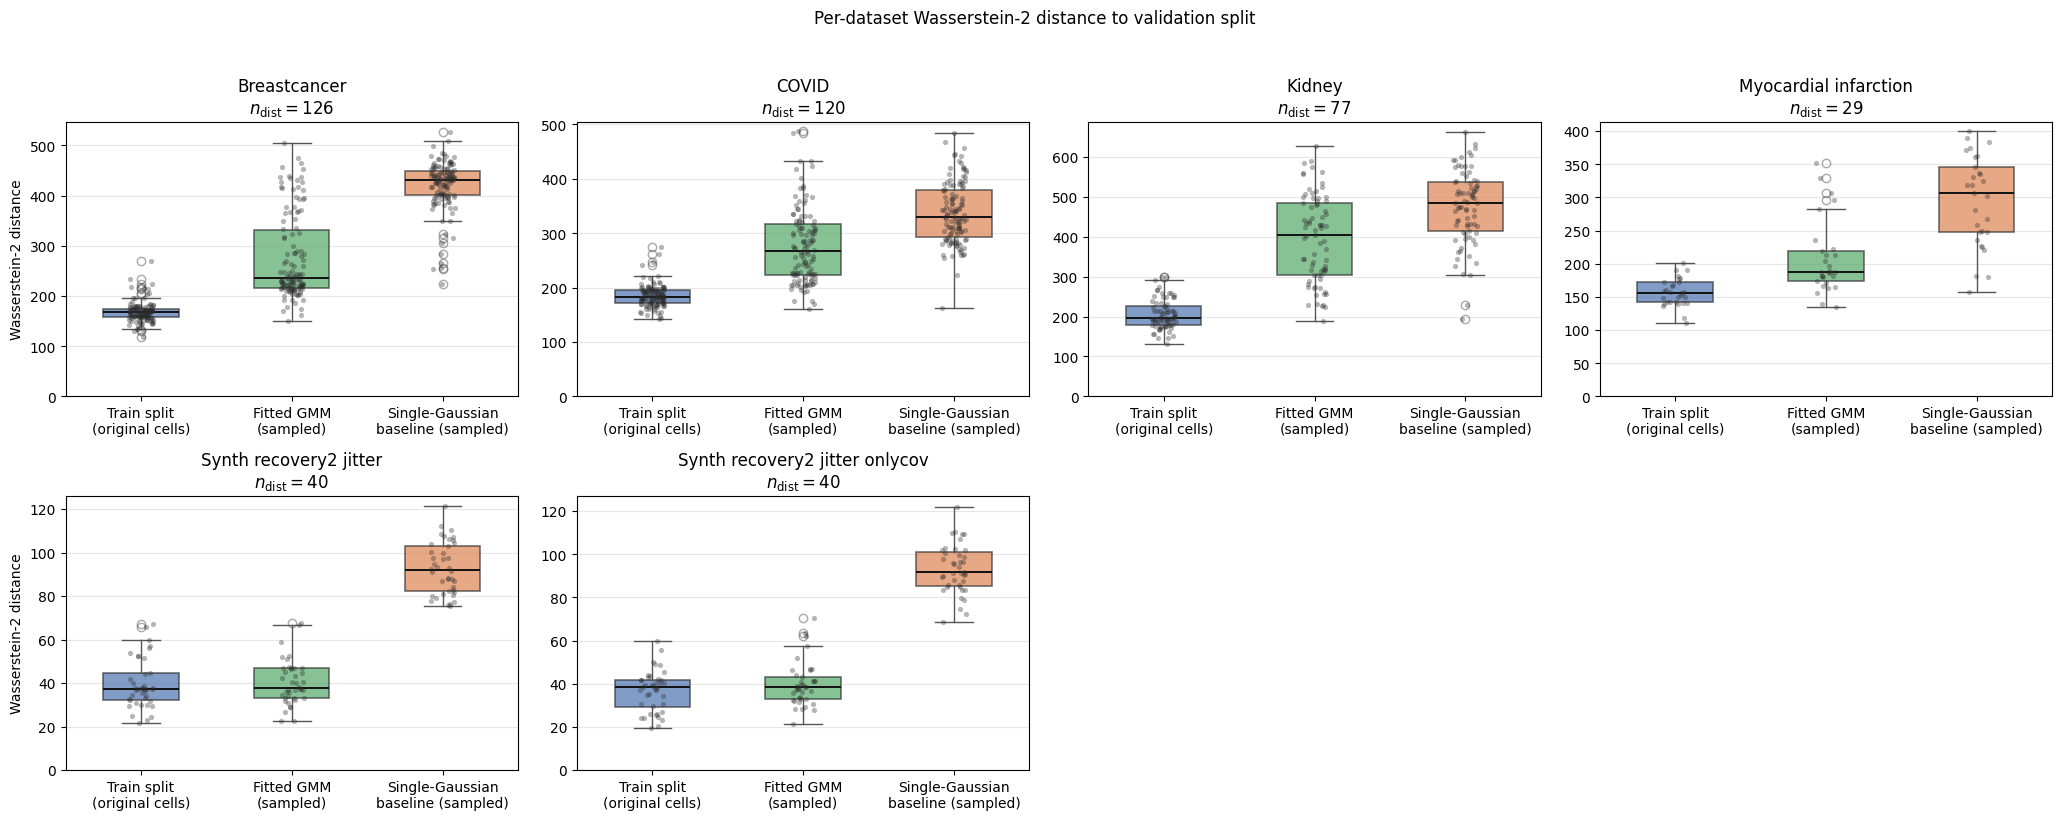

In [10]:
fig_distances, _ = plot_distance_triplet_panels(
    distribution_summary,
    dataset_cfg=config["datasets"],
    dataset_names=dataset_names,
)
distance_triplet_pdf = save_plot_pdf(fig_distances, "validation_distance_triplet_panels.pdf")

Saved ../data/generated_plots/appendix/gmm_validation/validation_train_vs_gmm_panels.pdf


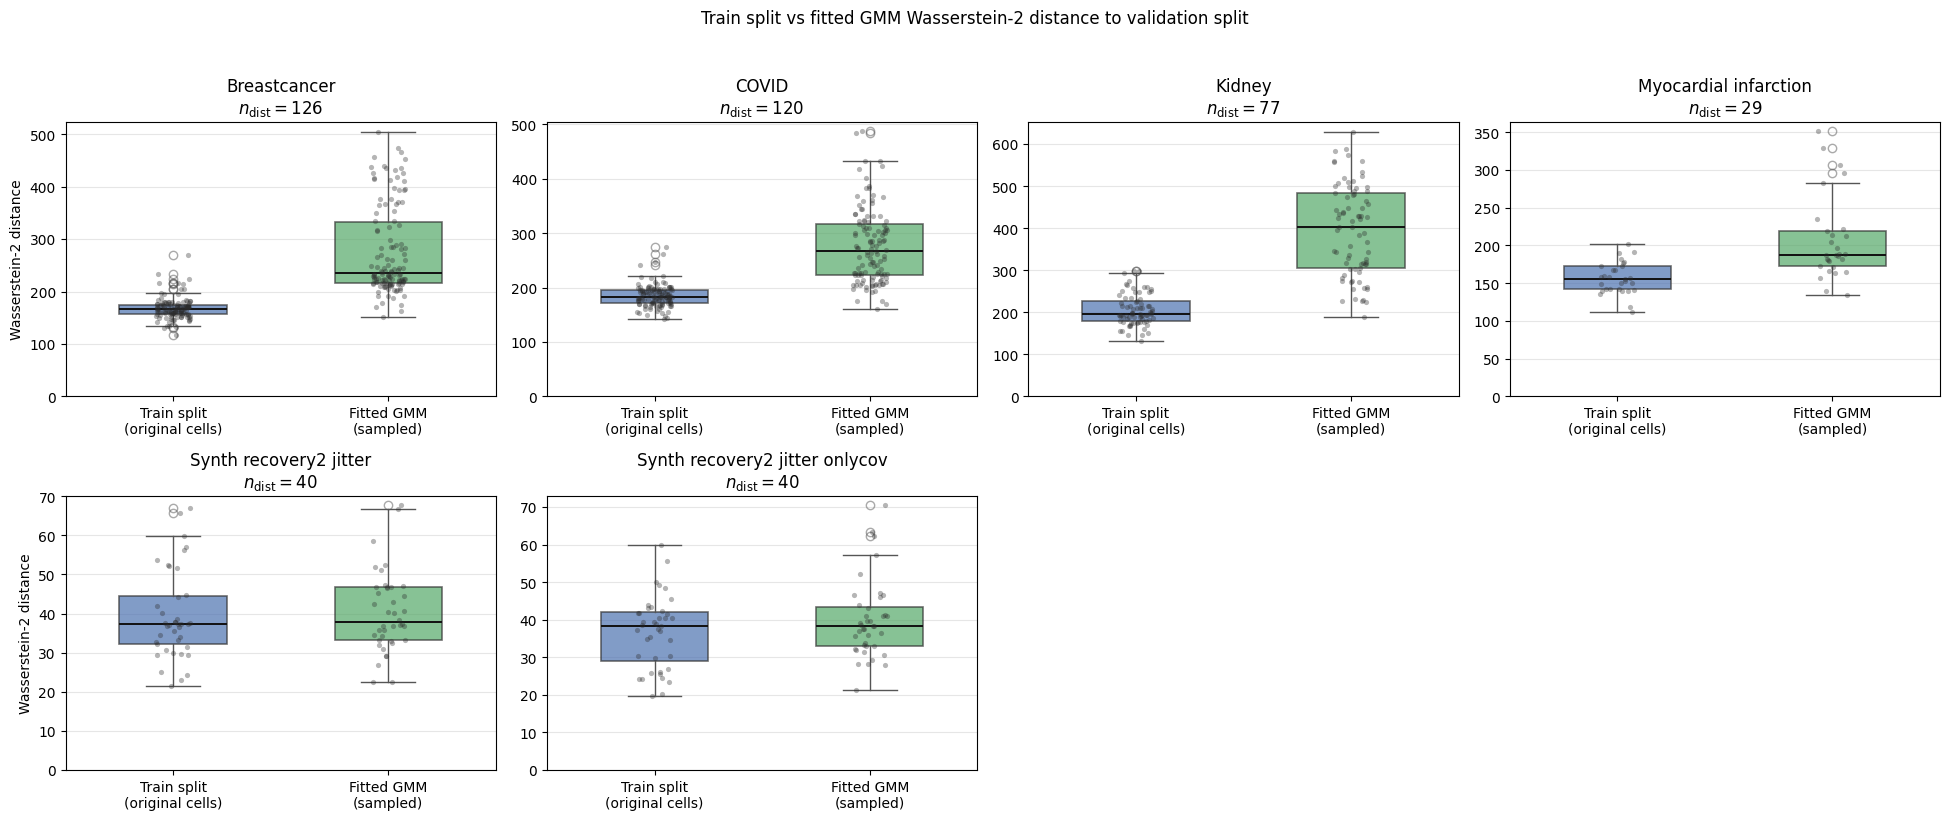

In [11]:
fig_train_gmm, _ = plot_train_gmm_panels(
    distribution_summary,
    dataset_cfg=config["datasets"],
    dataset_names=dataset_names,
)
train_gmm_pdf = save_plot_pdf(fig_train_gmm, "validation_train_vs_gmm_panels.pdf")